1. Importação das funções

In [3]:
%reload_ext autoreload
%autoreload 2

from IPython.display import Audio, display

from mandarinstudio.audio.recording import record_audio
from mandarinstudio.comparison.dtw import run_dtw
from mandarinstudio.comparison.evaluation import evaluate_pronunciation
from mandarinstudio.flashcards.creation import create_flashcard
from mandarinstudio.visualization.graphs import plot_graph

from mandarinstudio.config import AUDIO_USER_DIR

In [ ]:
flashcard = create_flashcard(
    hanzi="妈", 
    meaning="mãe",
    grammar=["妈", "[unk]"]
)

2026-09-18 20:25:34,704 [INFO] mandarinstudio.audio.reference: Generating reference audio via gTTS for: 妈...
2026-09-18 20:25:34,705 [WARNING] gtts.lang: 'zh-CN' has been deprecated, falling back to 'zh-CN'. This fallback will be removed in a future version.
2026-09-18 20:25:35,754 [INFO] mandarinstudio.audio.reference: Reference audio successfully saved to: C:\Users\Danyelle\Documents\PROJETOS\Mandarin Studio\data\audio\references\3471704d-aa2d-4576-bd75-194c5fbf6185.wav


2. Bloco de testes do pipeline completo

In [4]:
#ref_path = generate_audio_ref(flashcard.hanzi, flashcard.id)
display(Audio(data=flashcard.reference_audio_path, rate=16000))

user_path = record_audio(AUDIO_USER_DIR / 'user_audio.wav')
display(Audio(data=user_path, rate=16000))

NameError: name 'flashcard' is not defined

(<CategoryOptions.INCORRECT: 'incorrect'>, 45.74)


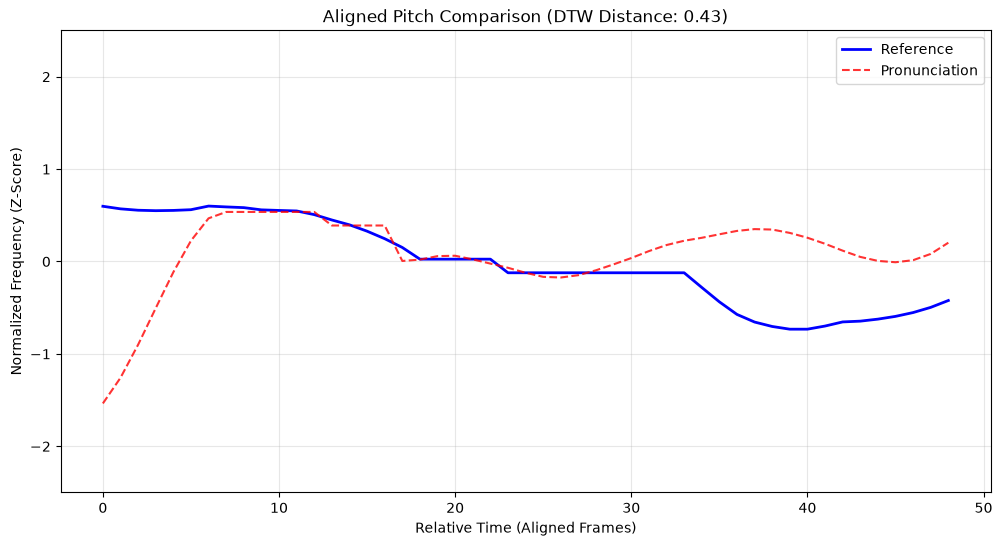

In [117]:
result = evaluate_pronunciation(flashcard, user_path)
print(result)

dtw_result = run_dtw(flashcard.reference_audio_path, user_path)
plot_graph(dtw_result.ref_pitch, dtw_result.user_pitch, dtw_result.path, dtw_result.avg_distance)